<a href="https://colab.research.google.com/github/HalfNHalf3/Final-Project-volleyball-overlay/blob/main/Volleyball_AI_Development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import shutil
from pathlib import Path
from google.colab import drive

# Clean up any local dummy folder that is blocking the mount
drive_path = Path("/content/drive")
if drive_path.exists() and not drive_path.is_mount():
    print("Cleaning up existing unmounted directory to prepare for mounting...")
    shutil.rmtree(drive_path, ignore_errors=True)

print("Mounting Google Drive...")
drive.mount("/content/drive", force_remount=True)

Cleaning up existing unmounted directory to prepare for mounting...
Mounting Google Drive...
Mounted at /content/drive


In [12]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VolleyballAI"
)

VIDEO_DIR = PROJECT_DIR / "videos" / "raw"
DATASET_DIR = PROJECT_DIR / "datasets"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
EXPORT_DIR = PROJECT_DIR / "exports"

for folder in [
    VIDEO_DIR,
    DATASET_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    EXPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders are ready.")

Project folders are ready.


In [ ]:
%pip install -q ultralytics opencv-python-headless fastapi uvicorn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.1 MB/s eta 0:00:00


In [ ]:
import cv2
import numpy as np
import torch
import ultralytics

print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
OpenCV: 4.14.0
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.183
CUDA available: False


In [16]:
from pathlib import Path
import cv2

# Let's search your Google Drive to find exactly where the video file is stored
drive_root = Path("/content/drive/MyDrive")
found_paths = list(drive_root.rglob("*volleyball vid 1min15*"))

if not found_paths:
    print("Could not find any file matching 'volleyball vid 1min15' in your Google Drive.")
    print("Please check if the video has finished uploading to Drive, or check its spelling.")
else:
    print(f"Found {len(found_paths)} matching file(s):")
    for path in found_paths:
        print(f"- {path}")

    # Use the first match found
    video_path = found_paths[0]
    print(f"\nUsing found video path: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if cap.isOpened():
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        duration = frame_count / fps if fps > 0 else 0

        print(f"\nResolution: {width} x {height}")
        print(f"FPS: {fps:.2f}")
        print(f"Frames: {frame_count}")
        print(f"Duration: {duration:.2f} seconds")
        cap.release()
    else:
        print("Could not open the found video file.")

Found 1 matching file(s):
- /content/drive/MyDrive/VolleyballAI/videos/raw/volleyball vid 1min15.mp4

Using found video path: /content/drive/MyDrive/VolleyballAI/videos/raw/volleyball vid 1min15.mp4

Resolution: 1920 x 1080
FPS: 30.00
Frames: 2257
Duration: 75.23 seconds


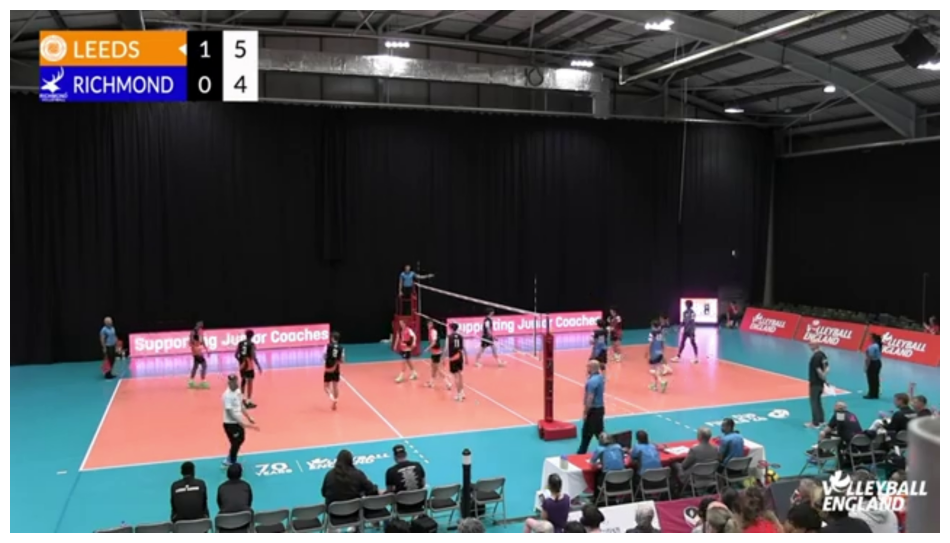

In [17]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(video_path))

cap.set(cv2.CAP_PROP_POS_MSEC, 5000)
success, frame = cap.read()
cap.release()

if success:
    frame_rgb = cv2.cvtColor(
        frame, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()
else:
    print("Could not read the selected frame.")